In [1]:
import os
import re
import glob
import json
import subprocess
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr

In [2]:
INPUT = "/kaggle/input/datasets/nocturnalnerd18"
USERNAME = "nocturnalnerd18"
OUT_DIR = "/kaggle/working/patch_llava_analysis"
os.makedirs(OUT_DIR, exist_ok=True)

N_LAYER, N_HEAD = 32, 32
GROUPS = ["visual", "text", "tail"]
DIRECTIONS = ["noising", "denoising"]

MIN_GROUP = 10
MIN_BIN = 5
N_PERM = 500
K_TOP = 20
MIN_LOGITS = 0.05
DRIVEN_TE = -1.0
UNIT_BINS = {"attribute": 3, "object": 4, "relation/reefknot": 8, "relation/amber": 3}
CONTRASTS = {
    "evidence": ("false_yes", "true_yes", 1, None),
    "evidence_matched": ("false_yes", "true_yes", 0, None),
    "matched_driven": ("false_yes", "true_yes", 0, "driven"),
}
UNITS = {
    "attribute": ("attribute", None),
    "object": ("object", None),
    "relation/reefknot": ("relation", "reefknot"),
    "relation/amber": ("relation", "amber"),
}
SURVIVOR_CONTRASTS = ["evidence_matched", "matched_driven"]


def batch_number(path):
    return int(re.search(r"_batch_(\d+)\.pt$", path).group(1))


def load_stage(tag):
    out, seen = [], set()
    pats = [f"{INPUT}/patch-llava-exact/{tag}_batch_*.pt"]
    if tag == "B":
        pats.append("/kaggle/input/datasets/*/patch-llava-exact-b*/B_batch_*.pt")
    for pat in pats:
        for path in sorted(glob.glob(pat), key=lambda p: (os.path.dirname(p), batch_number(p))):
            for e in torch.load(path):
                if e["question_id"] not in seen:
                    seen.add(e["question_id"])
                    out.append(e)
    return out


def cell_name(c):
    base = f"L{c['layer']} H{c['head']}" if c["kind"] == "head" else f"L{c['layer']} MLP"
    return f"{base} {c['group']}"


with open(f"{INPUT}/patch-llava-exact/cells_A.json") as f:
    cells_A = json.load(f)
names_A = [cell_name(c) for c in cells_A]
entries_A = [e for e in load_stage("A") if e["ok"]]
assert entries_A, "attach patch-llava-exact with stage A entries"
entries_B, cells_B = [], []
cells_B_paths = glob.glob("/kaggle/input/datasets/*/patch-llava-exact-b*/cells_B.json") + [f"{INPUT}/patch-llava-exact/cells_B.json"]
cells_B_paths = [p for p in cells_B_paths if os.path.exists(p)]
if cells_B_paths:
    with open(cells_B_paths[0]) as f:
        cells_B = json.load(f)
    entries_B = [e for e in load_stage("B") if e["ok"]]
    print(f"stage B shards found: {sorted({os.path.dirname(p) for p in glob.glob('/kaggle/input/datasets/*/patch-llava-exact-b*/B_batch_*.pt')})}")
names_B = [cell_name(c) for c in cells_B]
print(f"stage A: {len(entries_A)} entries, {len(cells_A)} cells | stage B: {len(entries_B)} entries, {len(cells_B)} cells")

atp = {}
need = {e["question_id"] for e in entries_A + entries_B}
for path in sorted(glob.glob(f"{INPUT}/atp-llava-noising/*_batch_*.pt"), key=lambda p: (os.path.basename(p).split("_batch_")[0], batch_number(p))):
    for e in torch.load(path):
        if e["question_id"] in need:
            atp[e["question_id"]] = {"head": e["head"], "mlp": e["mlp"]}
assert need <= set(atp), "attach atp-llava-noising"


def atp_value(a, c):
    x = a["head"][:, c["layer"], c["head"]] if c["kind"] == "head" else a["mlp"][:, c["layer"]]
    return float(x.sum() if c["group"] == "all" else x[GROUPS.index(c["group"])])


def make_tier(entries, names, cell_list, source_names):
    cols = []
    for e, src_names in zip(entries, source_names):
        index = {n: i for i, n in enumerate(src_names)}
        cols.append([index[n] for n in names])
    d = pd.DataFrame([{
        "question_id": e["question_id"], "hallucination_type": e["hallucination_type"], "source": e["source"], "split": e["split"],
        "stratum": e["stratum"], "sign": e["sign"], "delta_clean": e["delta_clean"], "delta_corrupt": e["delta_corrupt"],
    } for e in entries])
    d["row"] = np.arange(len(d))
    d["TE"] = d.delta_clean - d.delta_corrupt
    d["gap_clean"] = d.sign * d.delta_clean
    d["te_cls"] = np.where(d.stratum.eq("false_yes"), np.where(d.TE < DRIVEN_TE, "driven", "prior"), "none")
    sign = d.sign.to_numpy(dtype=np.float32)[:, None]
    noising = np.stack([e["noising"].numpy()[c] for e, c in zip(entries, cols)])
    denoising = np.stack([e["denoising"].numpy()[c] for e, c in zip(entries, cols)])
    atp_mat = np.array([[atp_value(atp[e["question_id"]], c) for c in cell_list] for e in entries])
    F = {"noising": (-sign * noising).astype(np.float32), "denoising": (sign * denoising).astype(np.float32)}
    return {"df": d, "F": F, "raw_noising": noising, "raw_denoising": denoising, "atp": atp_mat, "cells": cell_list, "names": names}


TIERS = {"full": make_tier(entries_A, names_A, cells_A, [names_A] * len(entries_A))}
if entries_B:
    entries_focus = entries_A + entries_B
    TIERS["focus"] = make_tier(entries_focus, names_B, cells_B, [names_A] * len(entries_A) + [names_B] * len(entries_B))
for tname, tier in TIERS.items():
    d = tier["df"]
    assert all(np.isfinite(tier["F"][k]).all() for k in DIRECTIONS)
    print(f"--- tier {tname}: {len(d)} questions, {len(tier['cells'])} cells ---")
    print(pd.crosstab([d.hallucination_type, d.source, d.split], [d.stratum, d.te_cls]))

stage B shards found: []
stage A: 300 entries, 157 cells | stage B: 0 entries, 40 cells
--- tier full: 300 questions, 157 cells ---
stratum                           false_yes       true_yes
te_cls                               driven prior     none
hallucination_type source   split                         
attribute          amber    test          5     7       12
                            train        28    26       54
                            val           4     8       12
object             pope     test          1     0        1
                            train         2     4        6
                            val           1     0        1
relation           amber    test          0     1        1
                            train         1     4        5
                            val           0     1        1
                   reefknot test          1     8        9
                            train         6    34       40
                            val           

In [3]:
for tname, tier in TIERS.items():
    ents = entries_A if tname == "full" else entries_A + entries_B
    chk = max(max(abs(e["check_noising"]), abs(e["check_denoising"])) for e in ents)
    base = max(max(abs(e["delta_clean"] - e["atp_delta_clean"]), abs(e["delta_corrupt"] - e["atp_delta_corrupt"])) for e in ents)
    print(f"tier {tname}: identity check max error {chk:.3f}, clean and corrupt delta vs attribution patching run max diff {base:.3f}")

tier = TIERS["full"]
d, N, Dn, A = tier["df"], tier["raw_noising"], tier["raw_denoising"], tier["atp"]
print(f"--- attribution patching vs exact noising on {N.size} entry-cells (stage A, full cell list) ---")
print(f"pooled spearman {spearmanr(A.ravel(), N.ravel())[0]:.3f} | slope of exact on atp {(A * N).sum() / (A ** 2).sum():.3f}")
rows = []
for j, c in enumerate(tier["cells"]):
    rows.append({"kind": c["kind"], "group": c["group"], "layer": c["layer"]})
meta_c = pd.DataFrame(rows)
for key in ["kind", "group"]:
    for val, idx in meta_c.groupby(key).groups.items():
        idx = list(idx)
        print(f"  {key} {val:7s} cells {len(idx):3d} | spearman {spearmanr(A[:, idx].ravel(), N[:, idx].ravel())[0]:.3f} | slope {(A[:, idx] * N[:, idx]).sum() / (A[:, idx] ** 2).sum():.3f}")
rec10, rec20, sgn = [], [], []
for i in range(len(d)):
    k = min(10, N.shape[1])
    top_e, top_a = set(np.argsort(-np.abs(N[i]))[:k]), set(np.argsort(-np.abs(A[i]))[:k])
    rec10.append(len(top_e & top_a) / k)
    k = min(20, N.shape[1])
    rec20.append(len(set(np.argsort(-np.abs(N[i]))[:k]) & set(np.argsort(-np.abs(A[i]))[:k])) / k)
    big = np.abs(N[i]) > 0.1 * np.abs(N[i]).max()
    sgn.append(float((np.sign(A[i][big]) == np.sign(N[i][big])).mean()))
print(f"per question top-10 recall {np.mean(rec10):.3f} | top-20 recall {np.mean(rec20):.3f} | sign agreement on large effects {np.mean(sgn):.3f}")

fy = d.stratum.eq("false_yes").to_numpy()
mean_n, mean_d, mean_a = N[fy].mean(0), Dn[fy].mean(0), A[fy].mean(0)
print(f"--- false_yes mean effects per cell ({fy.sum()} questions) ---")
print(f"noising vs denoising spearman {spearmanr(mean_n, mean_d)[0]:.3f} | atp vs exact noising {spearmanr(mean_a, mean_n)[0]:.3f}")
order = np.argsort(-np.abs(mean_n))[:15]
print(pd.DataFrame({"cell": [tier["names"][i] for i in order], "atp": mean_a[order].round(3), "exact_noising": mean_n[order].round(3), "exact_denoising": mean_d[order].round(3)}).to_string(index=False))

tier full: identity check max error 0.016, clean and corrupt delta vs attribution patching run max diff 0.016
--- attribution patching vs exact noising on 47100 entry-cells (stage A, full cell list) ---
pooled spearman 0.803 | slope of exact on atp 0.810
  kind head    cells  74 | spearman 0.909 | slope 0.915
  kind mlp     cells  83 | spearman 0.718 | slope 0.765
  group all     cells  75 | spearman 0.780 | slope 0.763
  group tail    cells  16 | spearman 0.871 | slope 0.947
  group text    cells  30 | spearman 0.818 | slope 0.814
  group visual  cells  36 | spearman 0.758 | slope 0.973
per question top-10 recall 0.579 | top-20 recall 0.672 | sign agreement on large effects 0.908
--- false_yes mean effects per cell (150 questions) ---
noising vs denoising spearman -0.335 | atp vs exact noising 0.821
        cell    atp  exact_noising  exact_denoising
 L28 MLP all -0.829         -0.817            1.111
L28 MLP tail -0.826         -0.814            1.114
 L17 MLP all  0.671          0.6

In [4]:
def unit_mask(d, unit):
    t, source = UNITS[unit]
    mask = d.hallucination_type.eq(t)
    if source is not None:
        mask &= d.source.eq(source)
    return mask


def build_strata(d, unit, g_a, g_b, splits, n_bins, a_filter, F):
    keep = unit_mask(d, unit) & d.stratum.isin([g_a, g_b]) & d.split.isin(splits)
    if a_filter is not None:
        keep &= d.stratum.ne(g_a) | d.te_cls.eq(a_filter)
    strata = []
    for _, sub in d[keep].groupby("source"):
        if n_bins > 1:
            edges = np.quantile(sub.gap_clean, np.linspace(0, 1, n_bins + 1)[1:-1])
            parts = [p for _, p in sub.groupby(np.digitize(sub.gap_clean, edges))]
            min_group = MIN_BIN
        else:
            parts, min_group = [sub], MIN_GROUP
        for part in parts:
            is_a = part.stratum.eq(g_a).to_numpy()
            if is_a.sum() < min_group or (~is_a).sum() < min_group:
                continue
            X = F[part.row.to_numpy()].astype(np.float64)
            strata.append((X, X ** 2, is_a))
    return strata


def effects(strata, masks):
    n_comp = strata[0][0].shape[1]
    d_sum, m_sum, w_sum = np.zeros(n_comp), np.zeros(n_comp), 0.0
    for (X, X2, _), mask in zip(strata, masks):
        na, nb = mask.sum(), (~mask).sum()
        mf = mask.astype(np.float64)
        sa, sa2 = mf @ X, mf @ X2
        sb, sb2 = X.sum(0) - sa, X2.sum(0) - sa2
        ma, mb = sa / na, sb / nb
        va, vb = (sa2 - na * ma ** 2) / (na - 1), (sb2 - nb * mb ** 2) / (nb - 1)
        sp = np.sqrt(np.maximum(((na - 1) * va + (nb - 1) * vb) / (na + nb - 2), 0))
        w = na * nb / (na + nb)
        d_sum += w * (ma - mb) / np.maximum(sp, 1e-6)
        m_sum += w * (ma - mb)
        w_sum += w
    return d_sum / w_sum, m_sum / w_sum


def perm_null(strata, seed=0):
    rng = np.random.default_rng(seed)
    null = np.empty(N_PERM)
    for b in range(N_PERM):
        dd, _ = effects(strata, [rng.permutation(mask) for _, _, mask in strata])
        null[b] = np.abs(dd).max()
    return null


def run_contrast(d, unit, cname, F):
    g_a, g_b, n_bins, a_filter = CONTRASTS[cname]
    if n_bins != 1:
        n_bins = UNIT_BINS[unit]
    train = build_strata(d, unit, g_a, g_b, ["train"], n_bins, a_filter, F)
    val = build_strata(d, unit, g_a, g_b, ["val"], n_bins, a_filter, F)
    test = build_strata(d, unit, g_a, g_b, ["test"], n_bins, a_filter, F)
    if not train or not val or not test:
        return None
    d_train, m_train = effects(train, [m for _, _, m in train])
    d_val, m_val = effects(val, [m for _, _, m in val])
    d_test, m_test = effects(test, [m for _, _, m in test])
    null95 = float(np.quantile(perm_null(train), 0.95))
    material = (np.abs(d_train) > null95) & (np.sign(m_train) == np.sign(m_val)) & (np.abs(m_train) >= MIN_LOGITS)
    return {
        "d_train": d_train, "m_train": m_train, "d_val": d_val, "m_val": m_val, "d_test": d_test, "m_test": m_test,
        "null95": float(null95), "n_a": int(sum(m.sum() for _, _, m in train)), "n_b": int(sum((~m).sum() for _, _, m in train)),
        "material": material,
    }


def report(label, r):
    mat = r["material"]
    agree = float((np.sign(r["m_train"][mat]) == np.sign(r["m_test"][mat])).mean()) if mat.any() else float("nan")
    print(f"{label:52s} {r['n_a']}/{r['n_b']} train | null95 {r['null95']:.3f} | material {int(mat.sum())} | test sign agreement {agree:.2f}")


results = {}
for tname, tier in TIERS.items():
    for unit in UNITS:
        for cname in CONTRASTS:
            for direction in DIRECTIONS:
                r = run_contrast(tier["df"], unit, cname, tier["F"][direction])
                if r is None:
                    if direction == DIRECTIONS[0]:
                        print(f"{tname:6s} {unit:18s} {cname:17s} not enough examples, skipped")
                    continue
                results[(tname, unit, cname, direction)] = r
                report(f"{tname} / {unit} / {cname} / {direction}", r)

full / attribute / evidence / noising                54/54 train | null95 0.671 | material 9 | test sign agreement 0.78
full / attribute / evidence / denoising              54/54 train | null95 0.695 | material 0 | test sign agreement nan
full   attribute          evidence_matched  not enough examples, skipped
full   attribute          matched_driven    not enough examples, skipped
full   object             evidence          not enough examples, skipped
full   object             evidence_matched  not enough examples, skipped
full   object             matched_driven    not enough examples, skipped
full   relation/reefknot  evidence          not enough examples, skipped
full   relation/reefknot  evidence_matched  not enough examples, skipped
full   relation/reefknot  matched_driven    not enough examples, skipped
full   relation/amber     evidence          not enough examples, skipped
full   relation/amber     evidence_matched  not enough examples, skipped
full   relation/amber     match

In [5]:
def both_directions(tname, unit, cname):
    rn, rd = results.get((tname, unit, cname, "noising")), results.get((tname, unit, cname, "denoising"))
    if rn is None or rd is None:
        return None
    return rn, rd, rn["material"] & rd["material"] & (np.sign(rn["m_train"]) == np.sign(rd["m_train"]))


for (tname, unit, cname, direction), r in results.items():
    if direction != "noising" or cname == "evidence":
        continue
    pair = both_directions(tname, unit, cname)
    if pair is None:
        continue
    rn, rd, both = pair
    names = TIERS[tname]["names"]
    top = np.argsort(-np.maximum(np.abs(rn["m_train"]), np.abs(rd["m_train"])))[:10]
    print(f"--- {tname} / {unit} / {cname}: material noising {int(rn['material'].sum())}, denoising {int(rd['material'].sum())}, both with the same sign {int(both.sum())} ---")
    print(pd.DataFrame({
        "cell": [names[i] for i in top], "noising": rn["m_train"][top].round(3), "noising_test": rn["m_test"][top].round(3),
        "denoising": rd["m_train"][top].round(3), "denoising_test": rd["m_test"][top].round(3),
        "mat_n": rn["material"][top], "mat_d": rd["material"][top],
    }).to_string(index=False))

tier = TIERS["focus"] if "focus" in TIERS else TIERS["full"]
d = tier["df"]
driven = d.te_cls.eq("driven").to_numpy()
if driven.sum() >= MIN_GROUP:
    te_mean = d.TE[driven].mean()
    share = tier["raw_denoising"][driven].mean(0) / te_mean
    order = np.argsort(-np.abs(share))[:12]
    print(f"--- sufficiency: mean denoising effect over driven false_yes ({int(driven.sum())} questions, mean TE {te_mean:+.2f}) as a share of the total effect ---")
    print(pd.DataFrame({"cell": [tier["names"][i] for i in order], "share_of_TE": share[order].round(3)}).to_string(index=False))
    noise_share = tier["raw_noising"][driven].mean(0) / (-te_mean)
    order = np.argsort(-np.abs(noise_share))[:12]
    print("--- necessity: mean noising effect over driven false_yes as a share of the total effect ---")
    print(pd.DataFrame({"cell": [tier["names"][i] for i in order], "share_of_TE": noise_share[order].round(3)}).to_string(index=False))

--- sufficiency: mean denoising effect over driven false_yes (49 questions, mean TE -2.43) as a share of the total effect ---
        cell  share_of_TE
 L28 MLP all       -0.555
L28 MLP tail       -0.555
 L17 MLP all        0.466
L17 MLP tail        0.459
 L16 MLP all        0.276
L16 MLP tail        0.262
  L4 MLP all       -0.240
 L15 MLP all        0.225
L29 MLP tail       -0.188
 L14 MLP all        0.185
 L30 MLP all        0.185
 L29 MLP all       -0.183
--- necessity: mean noising effect over driven false_yes as a share of the total effect ---
        cell  share_of_TE
 L17 MLP all        0.407
L17 MLP tail        0.393
 L28 MLP all       -0.375
L28 MLP tail       -0.371
L11 H26 text        0.292
 L11 H26 all        0.254
 L15 MLP all        0.246
 L10 MLP all        0.237
L11 H17 text        0.230
  L2 MLP all        0.219
 L20 MLP all       -0.205
 L11 H17 all        0.203


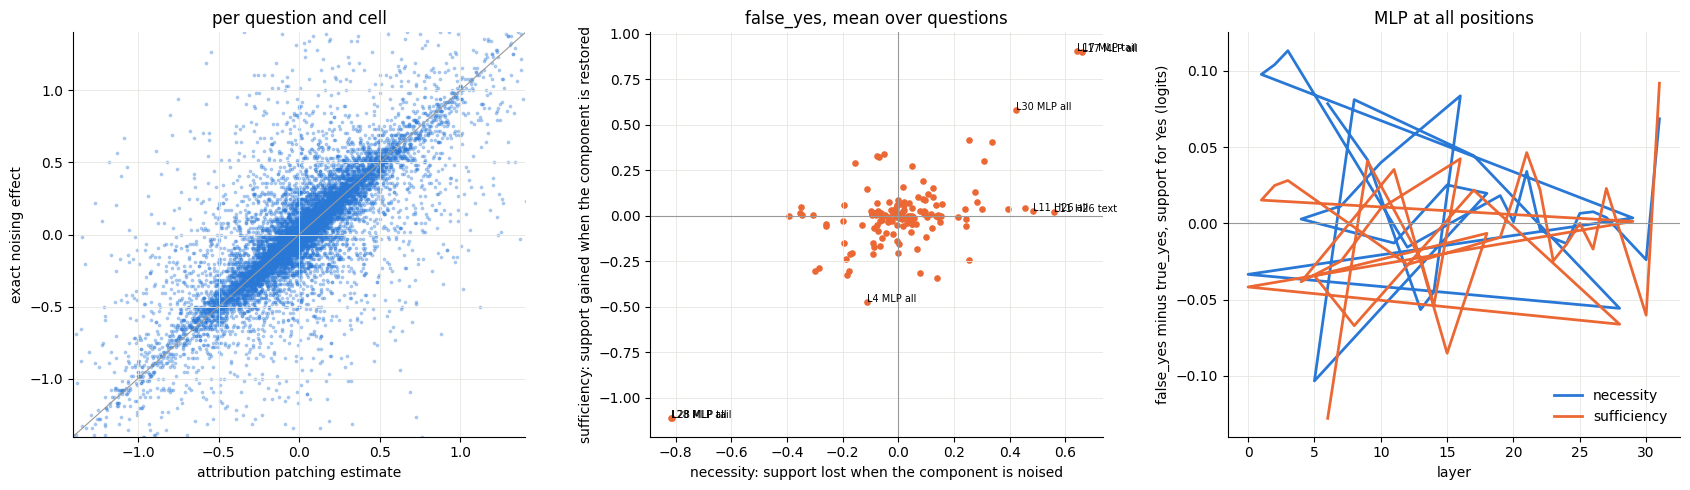

In [6]:
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#999999"
tier = TIERS["full"]
N, A = tier["raw_noising"], tier["atp"]
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sample = np.random.default_rng(0).choice(N.size, size=min(N.size, 20000), replace=False)
lim = np.percentile(np.abs(np.concatenate([A.ravel()[sample], N.ravel()[sample]])), 99.5)
axes[0].scatter(A.ravel()[sample], N.ravel()[sample], s=3, alpha=0.3, color=BLUE)
axes[0].plot([-lim, lim], [-lim, lim], color=GREY, lw=0.8)
axes[0].set_xlim(-lim, lim)
axes[0].set_ylim(-lim, lim)
axes[0].set_xlabel("attribution patching estimate")
axes[0].set_ylabel("exact noising effect")
axes[0].set_title("per question and cell")
fy = tier["df"].stratum.eq("false_yes").to_numpy()
mn, md = tier["F"]["noising"][fy].mean(0), tier["F"]["denoising"][fy].mean(0)
axes[1].scatter(mn, md, s=14, color=ORANGE)
for i in np.argsort(-np.maximum(np.abs(mn), np.abs(md)))[:8]:
    axes[1].annotate(tier["names"][i], (mn[i], md[i]), fontsize=7)
axes[1].axhline(0, color=GREY, lw=0.8)
axes[1].axvline(0, color=GREY, lw=0.8)
axes[1].set_xlabel("necessity: support lost when the component is noised")
axes[1].set_ylabel("sufficiency: support gained when the component is restored")
axes[1].set_title("false_yes, mean over questions")
DIVERGING = LinearSegmentedColormap.from_list("div", [BLUE, "#e8e8e4", ORANGE])
mlp_idx = [i for i, c in enumerate(tier["cells"]) if c["kind"] == "mlp" and c["group"] == "all"]
ct = tier["df"].stratum.eq("true_yes").to_numpy()
if mlp_idx and ct.any():
    layers_ = [tier["cells"][i]["layer"] for i in mlp_idx]
    for direction, color, label in [("noising", BLUE, "necessity"), ("denoising", ORANGE, "sufficiency")]:
        axes[2].plot(layers_, tier["F"][direction][fy][:, mlp_idx].mean(0) - tier["F"][direction][ct][:, mlp_idx].mean(0), color=color, lw=2, label=label)
    axes[2].axhline(0, color=GREY, lw=0.8)
    axes[2].set_xlabel("layer")
    axes[2].set_ylabel("false_yes minus true_yes, support for Yes (logits)")
    axes[2].set_title("MLP at all positions")
    axes[2].legend(frameon=False)
for ax in axes:
    ax.grid(color="#e5e5e2", lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/patching_overview.png", dpi=150)
plt.show()

In [7]:
survivors = {}
tier_name = "focus" if "focus" in TIERS else "full"
for unit in UNITS:
    for cname in SURVIVOR_CONTRASTS:
        pair = both_directions(tier_name, unit, cname)
        if pair is None:
            continue
        rn, rd, both = pair
        for i in np.flatnonzero(both):
            entry = survivors.setdefault(TIERS[tier_name]["names"][int(i)], {"cell": TIERS[tier_name]["cells"][int(i)], "evidence": {}})
            entry["evidence"][f"{unit}/{cname}"] = {"noising": float(rn["m_train"][i]), "denoising": float(rd["m_train"][i])}
print(f"{len(survivors)} cells are material in both directions with the same sign (tier {tier_name}):")
for name, s in sorted(survivors.items(), key=lambda kv: -max(abs(v["noising"]) for v in kv[1]["evidence"].values())):
    print(f"  {name:18s}", {k: (round(v['noising'], 3), round(v['denoising'], 3)) for k, v in s["evidence"].items()})

with open(f"{OUT_DIR}/survivors.json", "w") as f:
    json.dump(survivors, f)

with open(f"{OUT_DIR}/effects.json", "w") as f:
    json.dump({
        f"{tname}/{unit}/{cname}/{direction}": {
            "cells": TIERS[tname]["names"],
            "d_train": r["d_train"].tolist(), "d_val": r["d_val"].tolist(), "d_test": r["d_test"].tolist(),
            "m_train": r["m_train"].tolist(), "m_val": r["m_val"].tolist(), "m_test": r["m_test"].tolist(),
            "material": np.flatnonzero(r["material"]).tolist(), "null95": r["null95"], "n_a": r["n_a"], "n_b": r["n_b"],
        }
        for (tname, unit, cname, direction), r in results.items()
    }, f)

0 cells are material in both directions with the same sign (tier full):


In [8]:
with open(os.path.join(OUT_DIR, "dataset-metadata.json"), "w") as f:
    json.dump({
        "title": "patch-llava-effects",
        "id": f"{USERNAME}/patch-llava-effects",
        "subtitle": "Exact activation patching effect sizes and surviving components for LLaVA",
        "description": "Contrast statistics from patch-llava-exact. m_* vectors are mean differences in support for Yes (logits) between false_yes and matched true_yes questions, "
                       "d_* vectors Cohen's d, ranked on train, checked on val and reported on test. noising support is minus sign times the change in delta when a component is replaced by its corrupt activation "
                       "(the component's necessary contribution), denoising support is sign times the change when it is restored in the corrupt run (sufficiency). "
                       "Tier full is the complete cell list on the stage A questions, tier focus the cells chosen for stage B on all questions. Contrasts: evidence, evidence_matched (bins of the clean gap), matched_driven. "
                       "effects.json is keyed tier/unit/contrast/direction with the cell names alongside. survivors.json lists cells that are material in both directions with the same sign, the input to path patching.",
        "licenses": [{"name": "CC0-1.0"}],
    }, f)

r = subprocess.run(["kaggle", "datasets", "version", "-p", OUT_DIR, "-m", "analysis", "--dir-mode", "zip"], capture_output=True, text=True)
out = (r.stdout + r.stderr).strip()
if r.returncode != 0 or "error" in out.lower():
    r = subprocess.run(["kaggle", "datasets", "create", "-p", OUT_DIR, "--dir-mode", "zip"], capture_output=True, text=True)
    out += "\n" + (r.stdout + r.stderr).strip()
print(out)

Starting upload for file survivors.json
Upload successful: survivors.json (2B)
Starting upload for file effects.json
Upload successful: effects.json (43KB)
Starting upload for file patching_overview.png
Upload successful: patching_overview.png (413KB)
403 Client Error: Forbidden for url: https://api.kaggle.com/v1/datasets.DatasetApiService/CreateDatasetVersion

  0%|          | 0.00/2.00 [00:00<?, ?B/s]
100%|██████████| 2.00/2.00 [00:00<00:00, 8.13B/s]

  0%|          | 0.00/43.0k [00:00<?, ?B/s]
100%|██████████| 43.0k/43.0k [00:00<00:00, 173kB/s]

  0%|          | 0.00/413k [00:00<?, ?B/s]
100%|██████████| 413k/413k [00:00<00:00, 1.84MB/s]
Starting upload for file survivors.json
Error while trying to load upload info: KaggleObject.from_dict() got an unexpected keyword argument 'token'
Upload successful: survivors.json (2B)
Starting upload for file effects.json
Error while trying to load upload info: KaggleObject.from_dict() got an unexpected keyword argument 'token'
Upload successful: